# Next Steps

The following examples show various applications of witnessing nonclassicality in 1-qubit and 2-qubit systems. Nonclassical correlations can be observed in the classical data of quantum systems, **e.g.** Bell tests. We apply this idea in the following applications.

Proposed 1-qubit Applications:

1. Min Error Quantum State Discrimination
2. Quantum Dimensionality Witnessing

Proposed 2-qubit Applications:

1. CHSH violation
2. Device-Independent Key distribution Protocols

In [2]:
import qnetvo
import pennylane_kinesis as pk
import pennylane as qml
from pennylane import numpy as qnp
from matplotlib import pyplot as plt

An exception of type FileNotFoundException occurred. Arguments:
("Unable to find assembly 'Thorlabs.MotionControl.IntegratedStepperMotorsCLI'.",)

An error occured while importing pythonnet, time tagger, or kinesis software
setting `_TEST_MODE=True`


## Experiments with One Polarization Qubit and Projective Measurement

Consider a scenario with one sender ($A$) and one receiver ($B$) through some quantum channel. The sender emits a photon polarization qubit state $|\psi_x\rangle$  conditioned upon a classical input $x$. The receiver performs a projective measurement $|\phi_{b|y}\rangle\langle \phi^B_{b|y}|$ where the basis may be conditioned upon a classical input $y$ and $b\in\{0,1\}$. In the noiseless setting, the probabilities of this experiment are expressed

$$
P(b|x,y) = |\langle \phi_{b|y}|\psi_x\rangle|^2 = |\langle b |V_{y} U_{x} |0\rangle|^2
$$

where $U_x$ and $V_y$ are qubit unitaries and $b$ is the binary measurement result.

### Minimum Error Qubit State Discrimination

Let $x\in\{0,1\}$ label the ecoded state and $y=0$ be constant. The minimum state discrimination error is achieved when the output $b\in\{0,1\}$ matches the input $x$ with maximal success probability.

Objective:

$$
\max_{V, \{U_x\}_x} \sum_{x\in\{0,1\}} P(b=x|x) = \max_{V, \{U_x\}_x} \sum_{x\in\{0,1\}} |\langle x |V U_{x} |0\rangle|^2
$$

We demonstrate the optimization of state preparation and measurement. Some import applications that result from this test:
1. Optimizing the state encoding for a fixed "noisy" measurement decoding.
2. Optimizing the measurement decoding for a fixed "noisy" state encoding.
3. Certifying the qubit communication value of the noisy quantum channel.

(<Figure size 500x200 with 1 Axes>, <Axes: >)

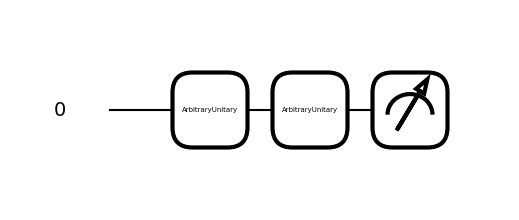

In [2]:
min_err_state_discrimination_ansatz = qnetvo.NetworkAnsatz(
    [qnetvo.PrepareNode(num_in=2, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3)],
    [qnetvo.MeasureNode(num_out=2, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3)]
)

@qml.qnode(qml.device("default.qubit", wires=[0]))
def draw_circ():
    min_err_state_discrimination_ansatz.fn(min_err_state_discrimination_ansatz.zero_network_settings())

    return qml.probs(wires=[0])

qml.draw_mpl(draw_circ)()

In [3]:
min_err_state_discrimination_cost = qnetvo.linear_probs_cost_fn(
    min_err_state_discrimination_ansatz,
    qnp.eye(2)
)

min_err_state_discrimination_opt_dict = qnetvo.gradient_descent(
    min_err_state_discrimination_cost,
    min_err_state_discrimination_ansatz.rand_network_settings(),
    num_steps=20,
    step_size=1,
    sample_width=1,
    verbose=False,
)

Text(0.5, 0, 'Optimization Iteration')

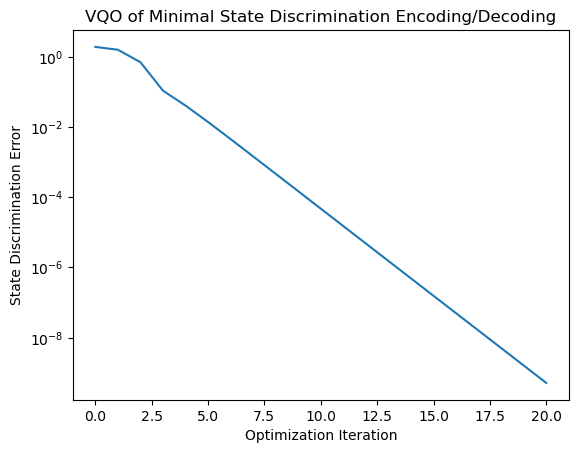

In [4]:
plt.title("VQO of Minimal State Discrimination Encoding/Decoding")

plt.semilogy(
    range(len(min_err_state_discrimination_opt_dict["scores"])),
    2 - qnp.array(min_err_state_discrimination_opt_dict["scores"]),
)


plt.ylabel("State Discrimination Error")
plt.xlabel("Optimization Iteration")

### Qubit Dimensionality Witnessing with qubit projective measurements

Things get more interesting when the receiver is given an input. 
Consider the case where $x\in\{0,\dots,n\}$, $y\in\{0,1\}$, and $b\in\{0,1\}$.

These dimensionality tests are semi-device independent, meaning that there is one qubit of communication from sender to receiver. The receiver's input $y$ leads to bounds on correlations of 1-bit of classical communication. These classical bounds can be violated when quantum communication is used. There are several applications that rely upon these violations:

1. [Semi-Device Independent Dimensionality Witnessing](https://journals.aps.org/prl/pdf/10.1103/PhysRevLett.112.140401?casa_token=9_qCJADufX4AAAAA%3ADvKMw3yVkjwLk1eV_ILqeTF_tZ6CoTWCBPo9cUVe7RauyJfrDCdxhSYFE_PBCYVFVzmlNhKPddxR3A)
2. [Semi-Device Independent Randomness Generation](https://arxiv.org/abs/1108.1480)
3. [Semi-Device Independent Key Distribution](https://arxiv.org/abs/1103.4105)
4. [Random Access Coding](https://arxiv.org/abs/1504.08105)

#### Minimal Qubit Dimensionality Witnessing 

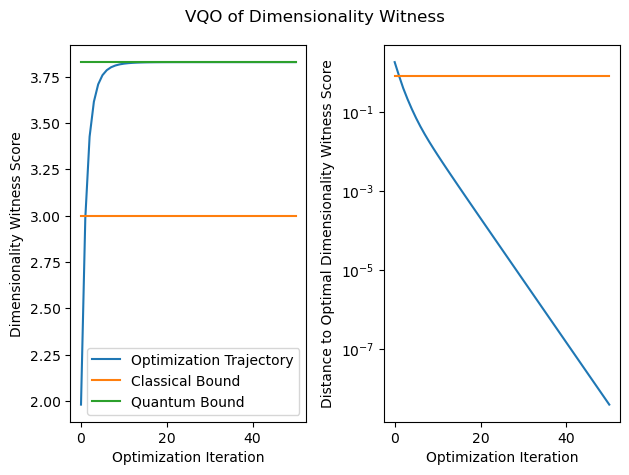

In [5]:
dim_wit_ansatz = qnetvo.NetworkAnsatz(
    [qnetvo.PrepareNode(num_in=3, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3)],
    [qnetvo.MeasureNode(num_out=2, num_in=2, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3)]
)

dim_wit_cost = qnetvo.linear_probs_cost_fn(
    dim_wit_ansatz,
    qnp.array([
        [1,1,1,-1,-1,0],
        [-1,-1,-1,1,1,0],
    ]),
)

dim_wit_opt_dict = qnetvo.gradient_descent(
    dim_wit_cost,
    dim_wit_ansatz.rand_network_settings(),
    step_size = 0.2,
    num_steps = 50,
    verbose=False,
    sample_width=1,
)

fig, (ax1, ax2) = plt.subplots(ncols=2)

fig.suptitle("VQO of Dimensionality Witness")

ax1.plot(
    range(len(dim_wit_opt_dict["scores"])),
    dim_wit_opt_dict["scores"],
    label="Optimization Trajectory"
)
ax1.plot(
    range(len(dim_wit_opt_dict["scores"])),
    [3] * len(dim_wit_opt_dict["scores"]),
    label="Classical Bound"
)

ax1.plot(
    range(len(dim_wit_opt_dict["scores"])),
    [1 + 2*qnp.sqrt(2)] * len(dim_wit_opt_dict["scores"]),
    label="Quantum Bound"
)

ax1.legend()

ax2.semilogy(
    range(len(dim_wit_opt_dict["scores"])),
    [1+2*qnp.sqrt(2)] - qnp.array(dim_wit_opt_dict["scores"]),
    label="optimization trajectory"
)
ax2.semilogy(
    range(len(dim_wit_opt_dict["scores"])),
    [1+2*qnp.sqrt(2) - 3] * len(dim_wit_opt_dict["scores"]),
    label="classical bound"
)

ax1.set_ylabel(r"Dimensionality Witness Score")
ax1.set_xlabel("Optimization Iteration")

ax2.set_ylabel("Distance to Optimal Dimensionality Witness Score")
ax2.set_xlabel("Optimization Iteration")

plt.tight_layout()

#### Random Access Code Advantage

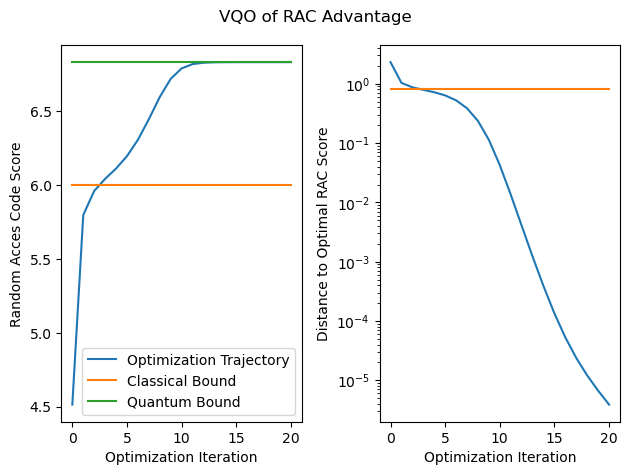

In [6]:
rac_ansatz = qnetvo.NetworkAnsatz(
    [qnetvo.PrepareNode(num_in=4, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3)],
    [qnetvo.MeasureNode(num_out=2, num_in=2, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3)]
)

rac_cost = qnetvo.linear_probs_cost_fn(
    rac_ansatz,
    qnp.array([
        [1,0,0,1,1,1,0,0],
        [0,1,1,0,0,0,1,1],
    ]),
)

rac_opt_dict = qnetvo.gradient_descent(
    rac_cost,
    rac_ansatz.rand_network_settings(),
    step_size = 0.6,
    num_steps = 20,
    verbose=False,
    sample_width=1,
)

fig, (ax1, ax2) = plt.subplots(ncols=2)

fig.suptitle("VQO of RAC Advantage")

ax1.plot(
    range(len(rac_opt_dict["scores"])),
    rac_opt_dict["scores"],
    label="Optimization Trajectory"
)
ax1.plot(
    range(len(rac_opt_dict["scores"])),
    [6] * len(rac_opt_dict["scores"]),
    label="Classical Bound"
)

ax1.plot(
    range(len(rac_opt_dict["scores"])),
    [4 + 2*qnp.sqrt(2)] * len(rac_opt_dict["scores"]),
    label="Quantum Bound"
)

ax1.legend()

ax2.semilogy(
    range(len(rac_opt_dict["scores"])),
    [4+2*qnp.sqrt(2)] - qnp.array(rac_opt_dict["scores"]),
    label="optimization trajectory"
)
ax2.semilogy(
    range(len(rac_opt_dict["scores"])),
    [4+2*qnp.sqrt(2) - 6] * len(rac_opt_dict["scores"]),
    label="classical bound"
)

ax1.set_ylabel(r"Random Acces Code Score")
ax1.set_xlabel("Optimization Iteration")

ax2.set_ylabel("Distance to Optimal RAC Score")
ax2.set_xlabel("Optimization Iteration")

plt.tight_layout()



# Protocols using Two-Qubit Entanglement

Consider a scenario with a two-qubit entanglement source that emits $|\psi^{AB}\rangle = (|HH\rangle + |VV\rangle)/\sqrt{2}$. The entangled state is measured by two independent detectors, Alice and Bob. Alice applies projective qubit measurement $\{|\phi^A_{a|x}\rangle\}_{x,a}$ and Bob applies the projective qubit measurements $\{|\phi^B_{b|y}\rangle\}_{b,y}$.

## Maximizing CHSH Violation

Objective

$$
\min_{\{|\phi^A_{a|x}\rangle\}_{x,a},\{|\phi^B_{b|y}\rangle\}_{b,y}} -S_{CHSH} = \min_{\{|\phi^A_{a|x}\rangle\}_{x,a},\{|\phi^B_{b|y}\rangle\}_{b,y}} -\left(\langle A_0 B_0\rangle + \langle A_0 B_1\rangle + \langle A_1 B_0 \rangle - \langle A_1 B_1\rangle\right)
$$

In the following we show that a CHSH violation can be optimized. Applications of CHSH violations include

1. Entanglement Certification
2. Device-Independent Key Distribution (see next example)
3. Device-Independent Randomness Generation



(<Figure size 600x300 with 1 Axes>, <Axes: >)

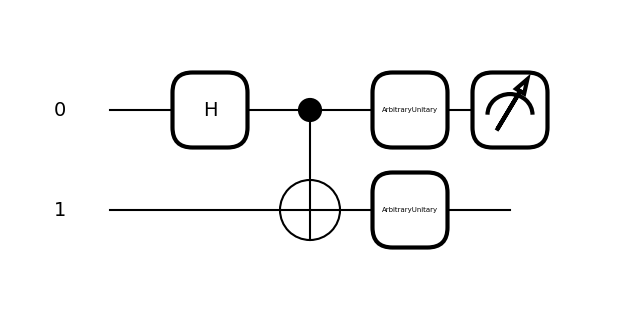

In [7]:
chsh_ansatz = qnetvo.NetworkAnsatz(
    [qnetvo.PrepareNode(wires=[0,1],ansatz_fn=qnetvo.ghz_state)],
    [
        qnetvo.MeasureNode(num_in=2, num_out=2, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3),
        qnetvo.MeasureNode(num_in=2, num_out=2, wires=[1], ansatz_fn=qml.ArbitraryUnitary, num_settings=3),
    ]
)

@qml.qnode(qml.device("default.qubit", wires=[0,1]))
def draw_circ():
    chsh_ansatz.fn(chsh_ansatz.zero_network_settings())

    return qml.probs(wires=[0])

qml.draw_mpl(draw_circ)()

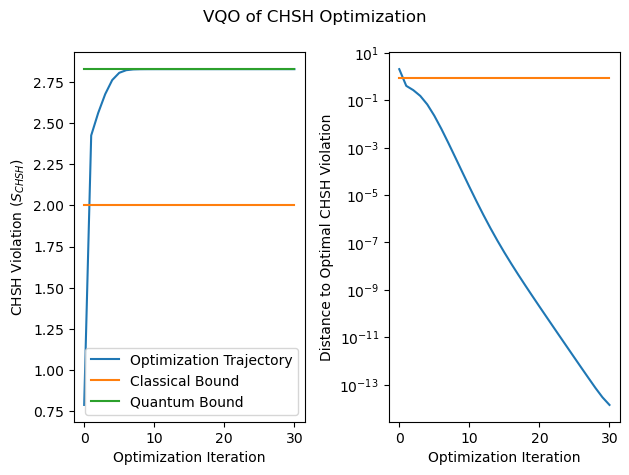

In [8]:
chsh_cost = qnetvo.chsh_inequality_cost_fn(chsh_ansatz)
# chsh_cost = qnetvo.linear_probs_cost_fn(
#     chsh_ansatz,
#     qnp.array([
#         [1, 1, 1, -1],
#         [-1, -1, -1, 1],
#         [-1, -1, -1, 1],
#         [1, 1, 1, -1],
#     ])
# )

chsh_opt_dict = qnetvo.gradient_descent(
    chsh_cost,
    chsh_ansatz.rand_network_settings(),
    step_size=0.5,
    num_steps=30,
    verbose=False,
    sample_width=1,
)

fig, (ax1, ax2) = plt.subplots(ncols=2)

fig.suptitle("VQO of CHSH Optimization")

ax1.plot(
    range(len(chsh_opt_dict["scores"])),
    chsh_opt_dict["scores"],
    label="Optimization Trajectory"
)
ax1.plot(
    range(len(chsh_opt_dict["scores"])),
    [2] * len(chsh_opt_dict["scores"]),
    label="Classical Bound"
)

ax1.plot(
    range(len(chsh_opt_dict["scores"])),
    [2*qnp.sqrt(2)] * len(chsh_opt_dict["scores"]),
    label="Quantum Bound"
)

ax1.legend()

ax2.semilogy(
    range(len(chsh_opt_dict["scores"])),
    2*qnp.sqrt(2) - qnp.array(chsh_opt_dict["scores"]),
    label="optimization trajectory"
)
ax2.semilogy(
    range(len(chsh_opt_dict["scores"])),
    [2*qnp.sqrt(2) - 2] * len(chsh_opt_dict["scores"]),
    label="classical bound"
)

ax1.set_ylabel(r"CHSH Violation ($S_{CHSH}$)")
ax1.set_xlabel("Optimization Iteration")

ax2.set_ylabel("Distance to Optimal CHSH Violation")
ax2.set_xlabel("Optimization Iteration")

plt.tight_layout()

## Device-Independent Quantum Key Distribution

In the following, we will train an apparatus for device independent key distribution where Alice has inputs $x\in\{0,1\}$ and Bob has inputs $y\in\{0,1,2\}$. This device independent key distribution protocol is discussed at a high-level ([https://doi.org/10.1145/3310974](https://dl.acm.org/doi/abs/10.1145/3310974))

Objective:

$$
\min_{\{|\phi^A_{a|x}\rangle\}_{a,x}, \{|\phi^B_{b|y}\}_{b,y} } -S_{CHSH}/2\sqrt{2} + Q_{Err}
$$

where $S_{CHSH}$ is the CHSH score and $Q_{Err}$ is the bit error rate on the distributed key.


The key rate $r$ of the key distribution protocol is lower bounded by the Devetak-Winter rate $r_{DW}$ defined as

$$
r \geq r_{DW} \equiv 1 - h(Q_{Err}) - h(\frac{1 + \sqrt{(S_{CHSH}/2)^2 - 1}}{2})
$$

where $h(x) = - x\log_2(x) - (1-x)\log_2(1-x)$ is the binary shannon entropy.

In [9]:
def diqkd_bit_err_fn(network_ansatz):
    
    probs_qnode = qnetvo.joint_probs_qnode(network_ansatz)
    
    def bit_err_fn(network_settings):
        probs = probs_qnode(network_ansatz.qnode_settings(network_settings, [[0], [0,2]]))
        bit_err = probs[1] + probs[2]
        
        return bit_err
    
    return bit_err_fn

def diqkd_cost_fn(network_ansatz):
    
    chsh_cost = qnetvo.chsh_inequality_cost_fn(network_ansatz)
    bit_err = diqkd_bit_err_fn(network_ansatz)
    
    def cost_fn(*network_settings):
        
        cost = chsh_cost(*network_settings)/(2*qnp.sqrt(2)) + bit_err(network_settings)
        return cost

    return cost_fn

def diqkd_rate_dw_fn(network_ansatz):
    chsh_cost = qnetvo.chsh_inequality_cost_fn(network_ansatz)
    bit_err = diqkd_bit_err_fn(network_ansatz)
    
    def rate_dw_fn(network_settings):
        
        S_chsh = -(chsh_cost(*network_settings))
        S_err = (1 + qnp.sqrt((max(S_chsh,2)/2)**2  - 1)) / 2
        
        Q_err = bit_err(network_settings)
                
        rate_dw = 1 - qnetvo.shannon_entropy([Q_err, 1-Q_err]) - qnetvo.shannon_entropy([S_err, 1 - S_err])
        
        return rate_dw
    
    return rate_dw_fn

In [10]:
diqkd_ansatz = qnetvo.NetworkAnsatz(
    [qnetvo.PrepareNode(wires=[0,1],ansatz_fn=qnetvo.ghz_state)],
    [
        qnetvo.MeasureNode(num_in=2, num_out=2, wires=[0], ansatz_fn=qml.ArbitraryUnitary, num_settings=3),
        qnetvo.MeasureNode(num_in=3, num_out=2, wires=[1], ansatz_fn=qml.ArbitraryUnitary, num_settings=3),
    ]
)

diqkd_cost = diqkd_cost_fn(diqkd_ansatz)

diqkd_opt_dict = qnetvo.gradient_descent(
    diqkd_cost,
    diqkd_ansatz.rand_network_settings(),
    step_size=1,
    num_steps=30,
    verbose=False,
    sample_width=1,
)

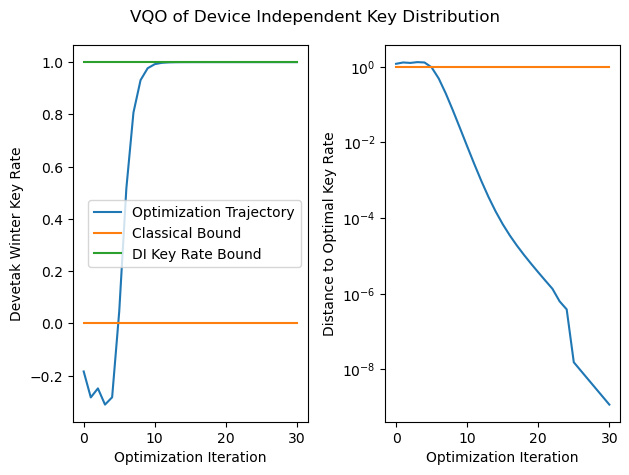

In [11]:

diqkd_bit_err = diqkd_bit_err_fn(diqkd_ansatz)
diqkd_chsh_cost = qnetvo.chsh_inequality_cost_fn(diqkd_ansatz)

devtak_winter_rate = diqkd_rate_dw_fn(diqkd_ansatz)

diqkd_rates = qnp.array(list(map(lambda settings: devtak_winter_rate(settings), diqkd_opt_dict["settings_history"])))


fig, (ax1, ax2) = plt.subplots(ncols=2)


ax1.plot(
    range(len(diqkd_rates)),
    diqkd_rates,
    label="Optimization Trajectory"
)
ax1.plot(
    range(len(diqkd_rates)),
    [0] * len(diqkd_rates),
    label="Classical Bound"
)

ax1.plot(
    range(len(diqkd_rates)),
    [1] * len(diqkd_rates),
    label="DI Key Rate Bound"
)

ax1.legend()

fig.suptitle("VQO of Device Independent Key Distribution")

ax2.semilogy(
    range(len(diqkd_rates)),
    1 - diqkd_rates,
    label="optimization trajectory"
)
ax2.semilogy(
    range(len(diqkd_rates)),
    [1] * len(diqkd_rates),
    label="classical bound"
)
ax1.set_ylabel("Devetak Winter Key Rate")
ax1.set_xlabel("Optimization Iteration")

ax2.set_ylabel("Distance to Optimal Key Rate")
ax2.set_xlabel("Optimization Iteration")

plt.tight_layout()

## Hong-Ou-Mandel Interference

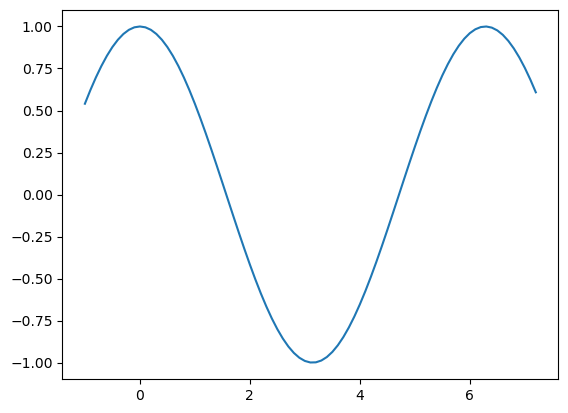

In [16]:
hom_ansatz = qnetvo.NetworkAnsatz(
    [qnetvo.PrepareNode(wires=[0,1], ansatz_fn=qnetvo.ghz_state)],
    [qnetvo.ProcessingNode(wires=[0], ansatz_fn=qnetvo.local_RY, num_settings=1)],
    [qnetvo.MeasureNode(wires=[0,1], num_out=4)],
)

hom_qnode = qnetvo.global_parity_expval_qnode(hom_ansatz)

def hom_cost(*settings):
    return -hom_qnode(hom_ansatz.qnode_settings(settings, [[],[0],[]]))


hom_cost([qnp.pi/1.5])

lin_range = qnp.arange(-1,2*qnp.pi  + 1, 0.1)
plt.plot(
    lin_range,
    -1 * qnp.array(list(map(hom_cost, lin_range)))
)

In [17]:
hom_opt_dict = qnetvo.gradient_descent(
    hom_cost,
    hom_ansatz.rand_network_settings(),
    step_size=1,
    num_steps=30,
    verbose=False,
    sample_width=1,
)

NameError: name 'diqkd_rates' is not defined

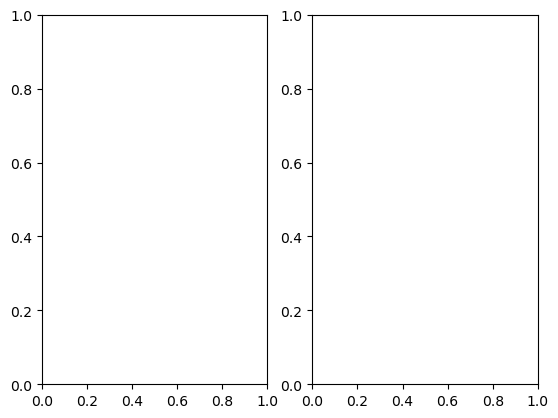